# Stage 1 search: genome, fitness cache, GA, PSO, memetic GA, DE and GWO

The Stage 1 search code for the Qubit Bottleneck plan. It picks the inputs of an 8-qubit circuit from the 144-column pool built in `pool_prep.ipynb` (128 PCA + 16 PLS per backbone, as angles in [0, pi]).

1. **Genome:** 8 picks from the pool, an encoding gate (RX, RY or H+RZ) and a rotation gate (RY, RX+RY or Rot). Picks go to qubits 0 to 7 in ascending pool order. No entanglers in the search; the entangler is tested on the final picks in week 4.
2. **Fitness:** the exact classical twin of the additive circuit, logistic regression on the circuit's sin/cos features (C = 0.01), trained on the 2,000 fitness frames and scored by frame AUC on the inner fitness frames. `ranking_check.ipynb` approved it (Spearman 0.996 against short-trained circuits). No gate penalty, since the search has no entanglers.
3. **Cache:** a genome always gets the same fitness, so every scored genome is kept in a store per backbone, written to disk and reloaded in a new session. A run still counts every distinct genome it asks for against its own budget, even when the store already has it, so runs stay independent and the store only saves time.
4. **Searches:** main methods random search, GA, PSO and memetic GA (GA plus a swap local search on the best genome each generation), 10 runs each; descriptive methods DE and GWO, 5 runs each. PSO, DE and GWO move vectors in [0, 1] that are decoded by random keys. 1,000 twin evaluations per run, every evaluation counted, local-search steps included. Every method on all three backbones. ACO is not included.
5. **Exploratory ablation** (`mode = "ablation"`): GA on L/14 with a held-out-manipulation term added to the fitness, PLS refit inside every held-out fold.

Validation, FF++ test and Celeb-DF are not touched here. Training the top genomes as real circuits and the single test run come later.

**Inputs (Add Input):**
- `malakkhaled202300369/nic-pool` (the `pool_prep` output, folder `pool/`), always.
- `malakkhaled202300369/nic-clip768-l14-dataset` (folder `features_l14/`), for the ablation only.
- To resume after a Kaggle session ends, also this notebook's earlier output.

**Settings:** Accelerator None (CPU). No installs are needed. Keep `smoke = True` for the first run: it checks the code end to end in a few minutes.

## 1. Settings

In [1]:
mode = "main"               # "main": the plan's searches; "ablation": GA with a held-out term on L/14
smoke = False                # True: small budget, checks the code end to end; False: the plan's runs

backbones = ["l14", "b16", "effb4"]   # CLIP ViT-L/14 (main), CLIP ViT-B/16, EfficientNet-B4
budget = 1000               # twin evaluations per run, every evaluation counted
runs = {"random": 10, "GA": 10, "PSO": 10, "memetic GA": 10, "DE": 5, "GWO": 5}   # runs per method, fixed in the plan
pop_size = 20               # GA population, DE vectors, random genomes per round
tournament_k = 3
elite = 2
p_cross = 0.9
p_mut_pick = 0.5            # chance that a child swaps one pick for a column it does not have
p_mut_gene = 0.1            # chance that the encoding gate, and separately the rotation gate, is drawn again
ls_swaps = 4                # memetic GA: swap moves tried on the best genome each generation
de_f = 0.5                  # DE/rand/1/bin
de_cr = 0.9
# PSO, Clerc and Kennedy constriction with phi 4.1 (chi 0.7298, c = 2.05 * chi), as in Phase 1
pso_inertia = 0.7298
pso_c1 = 1.49618
pso_c2 = 1.49618
pso_v_max = 0.2
stall_rounds = 5            # rounds with no new genome before half the population is replaced by random genomes
max_rounds = 100000         # hard stop, never reached in a normal run

encodings = ["RX", "RY", "H+RZ"]
rotations = ["RY", "RX+RY", "Rot"]
twin_c = 0.01               # the best C in ranking_check
fit_per_class = 1000        # fitness frames per class, as in every earlier search

n_jobs = 0                  # 0 = one job per CPU core
machine_name = "kaggle-farida"
seed = 0
out_dir = "/kaggle/working/genome_search"

if mode == "ablation":
    backbones = ["l14"]
    runs = {"GA + held-out": 10}
    out_dir += "_ablation"
if smoke:
    budget = 60
    runs = {m: 1 for m in runs}
    pop_size = 8
    out_dir += "_smoke"

# raw features per backbone (folder, file suffix), the same lookup as pool_prep; only the ablation needs them
raw_features = {"b16": ("features", "_clip.npy"), "l14": ("features_l14", "_clip.npy"), "effb4": ("features", "_effb4.npy")}

## 2. Imports

In [2]:
import os
# one thread per process, set before numpy loads
os.environ["OMP_NUM_THREADS"] = "1"
import re
import glob
import json
import time
import hashlib
import platform
import multiprocessing as mp
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

os.makedirs(out_dir, exist_ok=True)
os.makedirs(f"{out_dir}/runs", exist_ok=True)
if n_jobs == 0:
    n_jobs = os.cpu_count()
print("mode", mode, "| smoke", smoke, "| backbones", backbones, "| budget", budget, "| jobs", n_jobs)

mode main | smoke False | backbones ['l14', 'b16', 'effb4'] | budget 1000 | jobs 4


## 3. Loading a backbone

Several attached datasets hold files with the same name (`ffpp_train_rows.csv`, `features/...`), so every file is looked up by name and, where needed, by the folder it sits in. Everything else is read from the folder of the pool file.

`load_backbone` fills `D` with everything the fitness needs for one backbone. The worker processes are started after it runs, so they see the same data.

The fitness frames are the same 2,000 search-train frames as every earlier search (same code, same seed): 1,000 real and 1,000 fake, at most 2 frames per real video and 1 per fake video. The inner fitness frames are the 6,912 frames of the 54 inner pairs.

For the ablation, each held-out fold drops one manipulation's fakes from the fitness frames and keeps only the real frames and that manipulation's frames on the inner side. PLS is refit on the search-train frames without that manipulation (normalized features, `scale=True`, 16 components, as in `pool_prep`) and every column's angle range comes from the kept train frames, so nothing that builds the inputs has seen the held-out fakes. PCA uses no labels and stays fixed. A check first refits PLS on all search-train frames and compares it with the saved pool, so a mismatch in the attached features shows up before any search.

In [3]:
def find_all(filename):
    return sorted(glob.glob("/kaggle/input/**/" + filename, recursive=True))


def find_one(filename, folder=None):
    hits = find_all(filename)
    if folder is not None:
        hits = [p for p in hits if os.path.basename(os.path.dirname(p)) == folder]
    assert len(hits) == 1, (filename, folder, hits)
    return hits[0]


D = {}


def load_backbone(b):
    D.clear()
    pool_dir = os.path.dirname(find_one(f"{b}_ffpp_train_pool.npy"))
    pool = np.load(f"{pool_dir}/{b}_ffpp_train_pool.npy").astype(np.float64)
    scores = np.load(f"{pool_dir}/{b}_ffpp_train_scores.npy").astype(np.float64)
    rows = pd.read_csv(f"{pool_dir}/ffpp_train_rows.csv", dtype={"video_id": str})
    is_inner = np.load(f"{pool_dir}/ffpp_train_is_inner.npy").astype(bool)
    columns = json.load(open(f"{pool_dir}/columns.json"))
    assert len(pool) == len(scores) == len(rows) == len(is_inner)
    assert pool.shape[1] == len(columns)
    y = rows["label"].to_numpy()
    method = rows["method"].to_numpy()
    n_pca = sum(c.startswith("pca") for c in columns)
    n_pls = len(columns) - n_pca
    fake_methods = sorted(set(method[y == 1]))

    # per-column strength on search-train, recomputed here so the notebook does not need the strength files
    search = ~is_inner
    strength = []
    for j in range(len(columns)):
        auc = roc_auc_score(y[search], pool[search, j])
        strength.append(max(auc, 1 - auc))

    st_index = np.where(search)[0]
    st_rows = rows.iloc[st_index].copy()
    st_rows["row"] = st_index
    rng = np.random.default_rng(0)
    real_pick = st_rows[st_rows["label"] == 0].groupby("video_id").sample(n=2, random_state=0)["row"].to_numpy()
    fake_pick = st_rows[st_rows["label"] == 1].groupby(["method", "video_id"]).sample(n=1, random_state=0)["row"].to_numpy()
    fit_index = np.concatenate([rng.choice(real_pick, fit_per_class, replace=False),
                                rng.choice(fake_pick, fit_per_class, replace=False)])
    inner_index = np.where(is_inner)[0]

    folds = {"all": (fit_index, inner_index)}
    fold_pool = {"all": pool}
    if mode == "ablation":
        for m in fake_methods:
            fit_keep = (y[fit_index] == 0) | (method[fit_index] != m)
            inner_keep = (y[inner_index] == 0) | (method[inner_index] == m)
            folds[m] = (fit_index[fit_keep], inner_index[inner_keep])

        folder, suffix = raw_features[b]
        path = find_one("ffpp_train" + suffix, folder)
        raw_rows = pd.read_csv(os.path.join(os.path.dirname(path), "ffpp_train_rows.csv"), dtype={"video_id": str})
        assert (raw_rows["path"].to_numpy() == rows["path"].to_numpy()).all(), "raw features are not in pool row order"
        x = np.load(path).astype(np.float64)
        xn = x / np.linalg.norm(x, axis=1, keepdims=True)
        del x
        check = PLSRegression(n_components=n_pls, scale=True).fit(xn[search], y[search])
        saved = scores[:2000, n_pca:]
        diff = np.abs(check.transform(xn[:2000]) - saved).max() / np.abs(saved).max()
        print(b, "PLS refit against the saved pool, largest relative difference on 2000 rows: %.2e" % diff)
        assert diff < 1e-3, "the attached raw features do not reproduce the saved pool"
        for m in fake_methods:
            keep = (y == 0) | (method != m)
            pls = PLSRegression(n_components=n_pls, scale=True).fit(xn[search & keep], y[search & keep])
            s = np.hstack([scores[:, :n_pca], pls.transform(xn)])
            lo = np.percentile(s[keep], 0.5, axis=0)
            hi = np.percentile(s[keep], 99.5, axis=0)
            fold_pool[m] = np.clip((s - lo) / (hi - lo), 0.0, 1.0) * np.pi
        del xn

    D.update(backbone=b, columns=columns, n_cols=len(columns), n_pca=n_pca, y=y, strength=np.array(strength),
             fake_methods=fake_methods, folds=folds, fold_pool=fold_pool)
    print(f"{b}: pool {pool.shape}, {n_pca} PCA + {n_pls} PLS columns | "
          + " | ".join(f"{f} fit {len(fi)} inner {len(ii)}" for f, (fi, ii) in folds.items()))

## 4. Genome

A genome is `{"picks": 8 pool columns, "encoding": gate, "rotation": gate}`, always kept with the picks in ascending order, which is also the qubit order. Two genomes that build the same circuit have the same key, so the store treats them as one.

In [4]:
n_qubits = 8


def canonical(picks, encoding, rotation):
    return {"picks": sorted(int(p) for p in picks), "encoding": encoding, "rotation": rotation}


def key_of(g):
    return ".".join(D["columns"][p] for p in g["picks"]) + "|" + g["encoding"] + "|" + g["rotation"]


def random_genome(rng):
    return canonical(rng.choice(D["n_cols"], n_qubits, replace=False),
                     encodings[rng.integers(len(encodings))], rotations[rng.integers(len(rotations))])


def swap_one(g, rng):
    # one pick out, a column the genome does not have in
    picks = list(g["picks"])
    free = [j for j in range(D["n_cols"]) if j not in picks]
    picks[int(rng.integers(n_qubits))] = int(rng.choice(free))
    return canonical(picks, g["encoding"], g["rotation"])


def crossover(a, b, rng):
    # keep the columns both parents have, fill the rest from either parent's other picks
    shared = [p for p in a["picks"] if p in b["picks"]]
    others = [p for p in a["picks"] + b["picks"] if p not in shared]
    rng.shuffle(others)
    return canonical(shared + others[:n_qubits - len(shared)],
                     a["encoding"] if rng.random() < 0.5 else b["encoding"],
                     a["rotation"] if rng.random() < 0.5 else b["rotation"])


def mutate(g, rng):
    if rng.random() < p_mut_pick:
        g = swap_one(g, rng)
    encoding = encodings[rng.integers(len(encodings))] if rng.random() < p_mut_gene else g["encoding"]
    rotation = rotations[rng.integers(len(rotations))] if rng.random() < p_mut_gene else g["rotation"]
    return canonical(g["picks"], encoding, rotation)

## 5. Fitness: the twin

Without entanglers each qubit is measured on its own, so the readout is a weighted sum of one function per input, a fixed mix of sin x and cos x set by the encoding and the rotation (the same rule as `ranking_check`):
- RY encoding: the Bloch vector is (sin x, 0, cos x) and any rotation reaches both terms, so the features are [sin x, cos x].
- RX or H+RZ encoding with only an RY rotation: the rotation can only read the part of the Bloch vector already in its plane, which leaves cos x alone.
- RX or H+RZ encoding with RX+RY or Rot: both terms.

The twin is logistic regression on those features (standardized, C = 0.01), trained on the fitness frames and scored by frame AUC on the inner frames. In the ablation it is also trained once per held-out fold, and the fitness is the mean of the inner AUC and the mean held-out AUC.

In [5]:
def twin_features(x, g):
    if g["encoding"] != "RY" and g["rotation"] == "RY":
        return np.cos(x)
    return np.hstack([np.sin(x), np.cos(x)])


def twin_auc(x_fit, y_fit, x_inner, y_inner, g):
    model = make_pipeline(StandardScaler(), LogisticRegression(C=twin_c, max_iter=5000))
    model.fit(twin_features(x_fit, g), y_fit)
    return roc_auc_score(y_inner, model.predict_proba(twin_features(x_inner, g))[:, 1])


def score_genome(g):
    start = time.time()
    y = D["y"]
    aucs = {}
    for fold, (fi, ii) in D["folds"].items():
        p = D["fold_pool"][fold]
        aucs[fold] = twin_auc(p[fi[:, None], g["picks"]], y[fi], p[ii[:, None], g["picks"]], y[ii], g)
    result = {"key": key_of(g), "genome": json.dumps(g), "inner_auc": aucs["all"], "fitness": aucs["all"]}
    if mode == "ablation":
        held = [aucs[m] for m in D["fake_methods"]]
        result["held_out_mean"] = float(np.mean(held))
        result["held_out_worst"] = float(np.min(held))
        for m in D["fake_methods"]:
            result["held_out_" + m] = aucs[m]
        result["fitness"] = 0.5 * (aucs["all"] + result["held_out_mean"])
    result["seconds"] = time.time() - start
    return result


def fitness_check():
    # fixed genomes before any search; their val numbers are in pool_prep's bottleneck table
    first8 = list(range(n_qubits))
    strongest8 = np.argsort(D["strength"])[::-1][:n_qubits].tolist()
    pls8 = list(range(D["n_pca"], D["n_pca"] + n_qubits))
    table = []
    for label, picks in [("first 8 PCA", first8), ("strongest 8", strongest8), ("PLS 8", pls8)]:
        for encoding, rotation in [("RY", "Rot"), ("RX", "RY")]:
            r = score_genome(canonical(picks, encoding, rotation))
            table.append(dict({"genome": label, "gates": encoding + "/" + rotation},
                              **{k: v for k, v in r.items() if k not in ("key", "genome")}))
    print(pd.DataFrame(table).round(4).to_string(index=False))

## 6. The store and the budget

`store` maps a genome key to its scored result for the current backbone and setup. It is appended to `fitness_store_<backbone>_<setup id>.jsonl` as it grows, and any copy with the same name among the inputs is loaded first. The setup id is a hash of every setting that changes a score, so a store is never reused under different settings.

`Run.evaluate` takes a list of genomes and returns their fitness. A genome new to the run costs one evaluation from the run's budget, whether or not the store already has it; a genome the run has seen before is free; genomes past the budget get `None`. New genomes missing from the store are scored in parallel.

In [6]:
store = {}
store_path = None


def open_store(b):
    global store_path
    setup = {"backbone": b, "mode": mode, "encodings": encodings, "rotations": rotations, "twin_c": twin_c,
             "fit_per_class": fit_per_class, "seed": seed}
    setup_id = hashlib.md5(json.dumps(setup, sort_keys=True).encode()).hexdigest()[:10]
    name = f"fitness_store_{b}_{setup_id}.jsonl"
    store_path = f"{out_dir}/{name}"
    store.clear()
    for path in find_all(name) + ([store_path] if os.path.exists(store_path) else []):
        with open(path) as f:
            for line in f:
                r = json.loads(line)
                store[r["key"]] = r
    with open(store_path, "w") as f:
        for r in store.values():
            f.write(json.dumps(r) + "\n")
    print(b, "setup id", setup_id, "| genomes already in the store:", len(store))
    return setup_id


class Run:
    def __init__(self, method_name, run):
        self.method = method_name
        self.run = run
        self.seen = {}      # key -> fitness, in the order the run first asked for them
        self.log = []

    def left(self):
        return budget - len(self.seen)

    def evaluate(self, genomes, workers):
        new, new_keys = [], set()
        for g in genomes:
            k = key_of(g)
            if k not in self.seen and k not in new_keys and len(self.seen) + len(new) < budget:
                new.append(g)
                new_keys.add(k)
        todo = [g for g in new if key_of(g) not in store]
        scored = workers.map(score_genome, todo) if len(todo) > 0 else []
        with open(store_path, "a") as f:
            for r in scored:
                store[r["key"]] = r
                f.write(json.dumps(r) + "\n")
        scored_keys = set(r["key"] for r in scored)
        for g in new:
            r = store[key_of(g)]
            self.seen[r["key"]] = r["fitness"]
            self.log.append(dict(r, backbone=D["backbone"], method=self.method, run=self.run, eval=len(self.seen),
                                 from_store=r["key"] not in scored_keys))
        return [self.seen.get(key_of(g)) for g in genomes], len(new)


def scored_only(genomes, fit):
    keep = [i for i, f in enumerate(fit) if f is not None]
    return [genomes[i] for i in keep], [fit[i] for i in keep]


def immigrants(pop, fit, rng, run, workers):
    # the better half stays, the rest are new random genomes, so a stalled run still spends its full budget
    order = np.argsort(fit)[::-1][:pop_size // 2]
    new = [random_genome(rng) for _ in range(pop_size - len(order))]
    new_fit, _ = run.evaluate(new, workers)
    new, new_fit = scored_only(new, new_fit)
    return [pop[i] for i in order] + new, [fit[i] for i in order] + new_fit

## 7. Random search

Random genomes from the same space, `pop_size` per round, until the budget is spent. This is the control every method is compared with.

In [7]:
def random_search(run, workers):
    rng = np.random.default_rng(1000 + run)
    r = Run("random", run)
    rounds = 0
    while r.left() > 0 and rounds < max_rounds:
        rounds += 1
        r.evaluate([random_genome(rng) for _ in range(pop_size)], workers)
    return r

## 8. GA and memetic GA

The Phase 1 GA on the new genome: tournament selection, crossover that keeps shared columns, mutation (one pick swap, gate redraws) and elitism.

The memetic GA adds a swap local search: each generation the best genome tries `ls_swaps` swaps, each replacing one pick with a pool column it does not have, and takes the best swap if it beats the genome (best of k, the budgeted version of a greedy step). Every swap counts toward the budget.

If `stall_rounds` generations in a row add no new genome, the worse half of the population is replaced by random genomes, so every run spends its full budget.

The ablation's "GA + held-out" is the plain GA, scored by the fitness with the held-out term.

In [8]:
def tournament(pop, fit, rng):
    idx = rng.choice(len(pop), min(tournament_k, len(pop)), replace=False)
    return pop[max(idx, key=lambda i: fit[i])]


def local_search(g, f, run, rng, workers):
    candidates = [swap_one(g, rng) for _ in range(ls_swaps)]
    cand_fit, _ = run.evaluate(candidates, workers)
    best = None
    for c, cf in zip(candidates, cand_fit):
        if cf is not None and cf > f and (best is None or cf > best[1]):
            best = (c, cf)
    return best


def genetic_algorithm(run, workers, memetic, name):
    rng = np.random.default_rng((6000 if memetic else 2000) + run)
    r = Run(name, run)
    pop = [random_genome(rng) for _ in range(pop_size)]
    fit, _ = r.evaluate(pop, workers)
    pop, fit = scored_only(pop, fit)
    stale, rounds = 0, 0
    while r.left() > 0 and rounds < max_rounds:
        rounds += 1
        if memetic:
            b = int(np.argmax(fit))
            better = local_search(pop[b], fit[b], r, rng, workers)
            if better is not None:
                pop[b], fit[b] = better
            if r.left() == 0:
                break
        order = np.argsort(fit)[::-1]
        children = [pop[i] for i in order[:elite]]
        while len(children) < pop_size:
            a = tournament(pop, fit, rng)
            b = tournament(pop, fit, rng)
            child = crossover(a, b, rng) if rng.random() < p_cross else a
            children.append(mutate(child, rng))
        new_fit, n_new = r.evaluate(children, workers)
        pop, fit = scored_only(children, new_fit)
        stale = stale + 1 if n_new == 0 else 0
        if stale >= stall_rounds:
            pop, fit = immigrants(pop, fit, rng, r, workers)
            stale = 0
    return r

## 9. Random-key decoding

PSO, DE and GWO move vectors in [0, 1]: 144 keys (the 8 largest are the picks), then one gene for the encoding gate and one for the rotation gate, each split into three equal intervals. Each gene's option order is shuffled per run, as in Phase 1, so a pull toward the middle of [0, 1] cannot favour particular gates.

In [9]:
def choose(v, options):
    return options[min(int(v * len(options)), len(options) - 1)]


def option_orders(rng):
    return {"encoding": rng.permutation(encodings).tolist(), "rotation": rng.permutation(rotations).tolist()}


def decode(v, orders):
    n = D["n_cols"]
    return canonical(np.argsort(-v[:n])[:n_qubits], choose(v[n], orders["encoding"]), choose(v[n + 1], orders["rotation"]))

## 10. Differential evolution

DE/rand/1/bin. A trial replaces its target when its fitness is at least as high. If `stall_rounds` rounds add no new genome, the worse half of the vectors is drawn again.

In [10]:
def differential_evolution(run, workers):
    rng = np.random.default_rng(7000 + run)
    orders = option_orders(rng)
    r = Run("DE", run)
    n_dims = D["n_cols"] + 2
    x = rng.random((pop_size, n_dims))
    fit, _ = r.evaluate([decode(v, orders) for v in x], workers)
    fit = [f if f is not None else -np.inf for f in fit]
    stale, rounds = 0, 0
    while r.left() > 0 and rounds < max_rounds:
        rounds += 1
        trials = np.empty_like(x)
        for i in range(pop_size):
            a, b, c = rng.choice([j for j in range(pop_size) if j != i], 3, replace=False)
            mutant = x[a] + de_f * (x[b] - x[c])
            cross = rng.random(n_dims) < de_cr
            cross[rng.integers(n_dims)] = True
            trials[i] = np.clip(np.where(cross, mutant, x[i]), 0.0, 1.0)
        trial_fit, n_new = r.evaluate([decode(v, orders) for v in trials], workers)
        for i in range(pop_size):
            if trial_fit[i] is not None and trial_fit[i] >= fit[i]:
                x[i] = trials[i]
                fit[i] = trial_fit[i]
        stale = stale + 1 if n_new == 0 else 0
        if stale >= stall_rounds:
            worst = np.argsort(fit)[:pop_size // 2]
            x[worst] = rng.random((len(worst), n_dims))
            new_fit, _ = r.evaluate([decode(v, orders) for v in x[worst]], workers)
            for i, f in zip(worst, new_fit):
                fit[i] = f if f is not None else -np.inf
            stale = 0
    return r

## 11. PSO

The Phase 1 PSO on the new genome: constriction coefficients, velocities clipped to `pso_v_max`, positions clipped to [0, 1]. If `stall_rounds` rounds add no new genome, the worse half of the particles get new random positions and velocities and forget their personal best.

In [11]:
def pso(run, workers):
    rng = np.random.default_rng(3000 + run)
    orders = option_orders(rng)
    r = Run("PSO", run)
    n_dims = D["n_cols"] + 2
    x = rng.random((pop_size, n_dims))
    v = rng.uniform(-pso_v_max, pso_v_max, (pop_size, n_dims))
    p_best = x.copy()
    p_fit = np.full(pop_size, -np.inf)
    g_best = x[0].copy()
    g_fit = -np.inf
    stale, rounds = 0, 0
    while r.left() > 0 and rounds < max_rounds:
        rounds += 1
        fit, n_new = r.evaluate([decode(p, orders) for p in x], workers)
        for i in range(pop_size):
            if fit[i] is None:
                continue
            if fit[i] > p_fit[i]:
                p_best[i] = x[i]
                p_fit[i] = fit[i]
            if fit[i] > g_fit:
                g_best = x[i].copy()
                g_fit = fit[i]
        stale = stale + 1 if n_new == 0 else 0
        if stale >= stall_rounds:
            worst = np.argsort(p_fit)[:pop_size // 2]
            x[worst] = rng.random((len(worst), n_dims))
            v[worst] = rng.uniform(-pso_v_max, pso_v_max, (len(worst), n_dims))
            p_best[worst] = x[worst]
            p_fit[worst] = -np.inf
            stale = 0
            continue
        r1 = rng.random((pop_size, n_dims))
        r2 = rng.random((pop_size, n_dims))
        v = pso_inertia * v + pso_c1 * r1 * (p_best - x) + pso_c2 * r2 * (g_best - x)
        v = np.clip(v, -pso_v_max, pso_v_max)
        x = np.clip(x + v, 0.0, 1.0)
    return r

## 12. GWO

The Phase 1 GWO: the wolves move toward the three best positions found so far, and `a` falls from 2 to 0 as the budget is spent. If `stall_rounds` rounds add no new genome, the worse half of the wolves get new random positions.

In [12]:
def gwo(run, workers):
    rng = np.random.default_rng(5000 + run)
    orders = option_orders(rng)
    r = Run("GWO", run)
    n_dims = D["n_cols"] + 2
    x = rng.random((pop_size, n_dims))
    leaders = []
    stale, rounds = 0, 0
    while r.left() > 0 and rounds < max_rounds:
        rounds += 1
        fit, n_new = r.evaluate([decode(p, orders) for p in x], workers)
        for i in range(pop_size):
            if fit[i] is not None:
                leaders.append((fit[i], x[i].copy()))
        leaders = sorted(leaders, key=lambda t: t[0], reverse=True)[:3]
        stale = stale + 1 if n_new == 0 else 0
        if stale >= stall_rounds:
            order = np.argsort([f if f is not None else -np.inf for f in fit])[:pop_size // 2]
            x[order] = rng.random((len(order), n_dims))
            stale = 0
            continue
        a = 2 - 2 * (budget - r.left()) / budget
        new_x = np.zeros((pop_size, n_dims))
        for _, leader in leaders:
            big_a = 2 * a * rng.random((pop_size, n_dims)) - a
            big_c = 2 * rng.random((pop_size, n_dims))
            new_x += leader - big_a * np.abs(big_c * leader - x)
        x = np.clip(new_x / len(leaders), 0.0, 1.0)
    return r

## 13. Run the searches

For each backbone: load it, open its store, print the fitness check, then run every method. Each finished run writes its own log, `runs/<backbone>_<method>_<run>_b<budget>.csv`. A run whose file is in this session's output or among the inputs is skipped (and copied over), so a stopped notebook resumes where it left off. A run cut off halfway starts again, but its seed is fixed and the store already holds what it scored, so it replays fast.

In [13]:
searches = {
    "random": random_search,
    "GA": lambda run, workers: genetic_algorithm(run, workers, False, "GA"),
    "PSO": pso,
    "memetic GA": lambda run, workers: genetic_algorithm(run, workers, True, "memetic GA"),
    "DE": differential_evolution,
    "GWO": gwo,
    "GA + held-out": lambda run, workers: genetic_algorithm(run, workers, False, "GA + held-out"),
}
assert set(runs) <= set(searches), set(runs) - set(searches)


def run_file(b, method_name, run):
    return f"{b}_{re.sub('[^A-Za-z0-9]+', '_', method_name)}_{run}_b{budget}.csv"


setup_ids = {}
start_all = time.time()
for b in backbones:
    load_backbone(b)
    setup_ids[b] = open_store(b)
    fitness_check()
    with mp.get_context("fork").Pool(n_jobs) as workers:
        for method_name, n_runs in runs.items():
            for run in range(n_runs):
                name = run_file(b, method_name, run)
                if os.path.exists(f"{out_dir}/runs/{name}"):
                    print(f"{b} {method_name:13s} run {run}: already done in this session")
                    continue
                earlier = [p for p in find_all(name) if os.path.basename(os.path.dirname(p)) == "runs"]
                if len(earlier) > 0:
                    pd.read_csv(earlier[0]).to_csv(f"{out_dir}/runs/{name}", index=False)
                    print(f"{b} {method_name:13s} run {run}: done in an earlier session, copied")
                    continue
                t0 = time.time()
                r = searches[method_name](run, workers)
                log = pd.DataFrame(r.log)
                log.to_csv(f"{out_dir}/runs/{name}", index=False)
                best = log.loc[log["fitness"].idxmax()]
                print(f"{b} {method_name:13s} run {run}: {len(r.seen)} genomes ({int(log['from_store'].sum())} from the store), "
                      f"best fitness {best['fitness']:.4f}, {best['key']}, {time.time() - t0:.0f} s")
print("all runs done in %.1f min" % ((time.time() - start_all) / 60))

l14: pool (46076, 144), 128 PCA + 16 PLS columns | all fit 2000 inner 6912
l14 setup id ad1231af12 | genomes already in the store: 0
     genome  gates  inner_auc  fitness  seconds
first 8 PCA RY/Rot     0.7343   0.7343   0.0321
first 8 PCA  RX/RY     0.7297   0.7297   0.0108
strongest 8 RY/Rot     0.8332   0.8332   0.0134
strongest 8  RX/RY     0.8306   0.8306   0.0126
      PLS 8 RY/Rot     0.8658   0.8658   0.0132
      PLS 8  RX/RY     0.8678   0.8678   0.0113
l14 random        run 0: 1000 genomes (0 from the store), best fitness 0.8293, pca29.pca38.pca71.pca86.pca107.pca108.pls0.pls1|RX|RY, 6 s
l14 random        run 1: 1000 genomes (0 from the store), best fitness 0.8390, pca7.pca80.pca97.pca115.pls0.pls1.pls6.pls14|H+RZ|RX+RY, 5 s
l14 random        run 2: 1000 genomes (0 from the store), best fitness 0.8619, pca37.pca112.pls0.pls1.pls2.pls4.pls6.pls7|RX|RY, 5 s
l14 random        run 3: 1000 genomes (0 from the store), best fitness 0.8405, pca32.pca63.pca103.pca121.pls0.pls1.pls4.

## 14. Summary

Best fitness per run, and the best fitness so far against genomes evaluated (the anytime curve), mean over runs per method. Fitness only: validation and test come with the real circuits.

backbone     method  run  genomes  best fitness  inner auc  eval of best
     b16         DE    0     1000        0.7682     0.7682           974
     b16         DE    1     1000        0.8233     0.8233           959
     b16         DE    2     1000        0.8306     0.8306           957
     b16         DE    3     1000        0.7860     0.7860           680
     b16         DE    4     1000        0.8087     0.8087           972
     b16         GA    0     1000        0.8398     0.8398           834
     b16         GA    1     1000        0.8404     0.8404           542
     b16         GA    2     1000        0.8421     0.8421           892
     b16         GA    3     1000        0.8430     0.8430           684
     b16         GA    4     1000        0.8380     0.8380           885
     b16         GA    5     1000        0.8407     0.8407           757
     b16         GA    6     1000        0.8310     0.8310           808
     b16         GA    7     1000        0.8399    

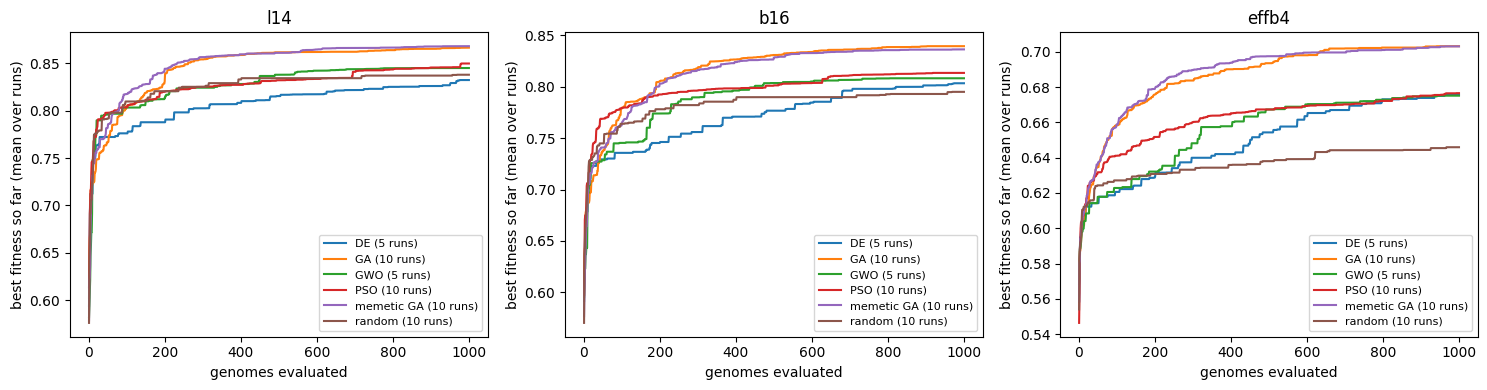

In [14]:
logs = pd.concat([pd.read_csv(p) for b in backbones
                  for p in sorted(glob.glob(f"{out_dir}/runs/{b}_*_b{budget}.csv"))], ignore_index=True)
logs.to_csv(f"{out_dir}/search_log.csv", index=False)

summary = []
for (b, method_name, run), g in logs.groupby(["backbone", "method", "run"]):
    best = g.loc[g["fitness"].idxmax()]
    row = {"backbone": b, "method": method_name, "run": run, "genomes": len(g), "best fitness": best["fitness"],
           "inner auc": best["inner_auc"], "eval of best": best["eval"], "best genome": best["key"]}
    if mode == "ablation":
        row["held-out mean"] = best["held_out_mean"]
        row["held-out worst"] = best["held_out_worst"]
    summary.append(row)
summary = pd.DataFrame(summary)
summary.to_csv(f"{out_dir}/summary.csv", index=False)
print(summary.drop(columns=["best genome"]).round(4).to_string(index=False))
print()
print(summary.groupby(["backbone", "method"])["best fitness"].agg(["count", "mean", "std", "min", "max"]).round(4).to_string())

fig, axes = plt.subplots(1, len(backbones), figsize=(5 * len(backbones), 4), squeeze=False)
for ax, b in zip(axes[0], backbones):
    for method_name, g in logs[logs["backbone"] == b].groupby("method"):
        curves = []
        for _, gr in g.groupby("run"):
            c = gr.sort_values("eval")["fitness"].cummax().to_numpy()
            curves.append(np.pad(c, (0, budget - len(c)), mode="edge"))
        ax.plot(np.arange(1, budget + 1), np.mean(curves, axis=0), label=f"{method_name} ({len(curves)} runs)")
    ax.set_title(b)
    ax.set_xlabel("genomes evaluated")
    ax.set_ylabel("best fitness so far (mean over runs)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{out_dir}/anytime.png", dpi=150)
plt.show()

## 15. Run log

In [15]:
info = {"finished": time.strftime("%Y-%m-%d %H:%M:%S"), "machine": machine_name, "mode": mode, "smoke": smoke,
        "backbones": backbones, "budget": budget, "runs": runs, "pop_size": pop_size, "tournament_k": tournament_k,
        "elite": elite, "p_cross": p_cross, "p_mut_pick": p_mut_pick, "p_mut_gene": p_mut_gene, "ls_swaps": ls_swaps,
        "de_f": de_f, "de_cr": de_cr, "pso_inertia": pso_inertia, "pso_c1": pso_c1, "pso_c2": pso_c2,
        "pso_v_max": pso_v_max, "stall_rounds": stall_rounds, "twin_c": twin_c, "setup_ids": setup_ids,
        "n_jobs": n_jobs, "total_minutes": round((time.time() - start_all) / 60, 1),
        "python": platform.python_version(), "numpy": np.__version__, "sklearn": sklearn.__version__}
with open(f"{out_dir}/runs.jsonl", "a") as f:
    f.write(json.dumps(info) + "\n")
!ls -lh {out_dir}

total 72M
-rw-r--r-- 1 root root 136K Nov 26 15:03 anytime.png
-rw-r--r-- 1 root root  13M Nov 26 14:58 fitness_store_b16_7f9966328b.jsonl
-rw-r--r-- 1 root root  13M Nov 26 15:03 fitness_store_effb4_34d38d3f0c.jsonl
-rw-r--r-- 1 root root  13M Nov 26 14:53 fitness_store_l14_ad1231af12.jsonl
drwxr-xr-x 2 root root  12K Nov 26 15:03 runs
-rw-r--r-- 1 root root  664 Nov 26 15:03 runs.jsonl
-rw-r--r-- 1 root root  33M Nov 26 15:03 search_log.csv
-rw-r--r-- 1 root root  17K Nov 26 15:03 summary.csv
